<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Content_based_filtering_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Content-Based Filtering with a Neural Network = Matching user and item *features*
#### In this file I walk through the deep-learning approach to recommendations.

In the previous notebook (collaborative filtering) the model only knew *who rated what*. Now I also give it **features**:
- about each **user** (e.g. their average rating per genre), and
- about each **item** (e.g. which genres a movie belongs to, its year).

Content-based filtering asks: *"how well do this user's needs match this item's attributes?"* The trick that makes it work is a **two-tower** network:

```
user features -> [user network] -> vector v_u  (length 16)  \
                                                              >-- dot product --> predicted rating
item features -> [item network] -> vector v_m  (length 16)  /
```

Each tower turns its raw features into a *vector of the same length*; the dot product of the two vectors is the predicted rating. After training, the item vectors can also be reused to find **similar items**.

> The course lab uses TensorFlow/Keras and a real movie dataset. I first implement the network in plain NumPy (so I understand the maths of the training), then show the same model in Keras at the end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The data (simulated)
- 6 genres. Each **movie** has a multi-hot genre vector plus a (scaled) release year.
- Each **user** has a hidden taste for each genre; the user *features* are their average observed rating per genre (like the lab's per-genre average columns).
- A rating depends on how much the user's taste matches the movie's genres.

In [2]:
rng = np.random.default_rng(0)
genres = ["Action", "Comedy", "Drama", "Sci-Fi", "Romance", "Horror"]
n_users, n_items, G = 120, 150, len(genres)

item_genres = (rng.random((n_items, G)) < 0.28).astype(float)
item_genres[item_genres.sum(1) == 0, rng.integers(0, G)] = 1                  # every movie has >= 1 genre
year = rng.uniform(0, 1, (n_items, 1))
item_feat = np.hstack([item_genres, year])                                       # 7 item features

taste = rng.normal(0, 1, (n_users, G))                                           # hidden: how much each user likes each genre
def true_rating(u, i):
    match = taste[u] @ item_genres[i] / np.maximum(item_genres[i].sum(), 1)
    return np.clip(np.round((3 + 1.6 * match + rng.normal(0, 0.3)) * 2) / 2, 0.5, 5)

# observe ~25% of all (user, movie) pairs
pairs = [(u, i) for u in range(n_users) for i in range(n_items) if rng.random() < 0.25]
ratings = np.array([true_rating(u, i) for u, i in pairs])
pairs = np.array(pairs)
print("rated pairs:", len(pairs), "| rating mean:", ratings.mean().round(2))

# split the ratings first, so the user features below only ever see TRAINING ratings (no leakage into the test set)
perm = np.random.default_rng(1).permutation(len(pairs))
n_tr = int(0.8 * len(pairs)); tr, te = perm[:n_tr], perm[n_tr:]

# user features = average rating per genre, computed from the training ratings the user gave
user_feat = np.zeros((n_users, G))
for u in range(n_users):
    for g in range(G):
        mask = (pairs[tr, 0] == u) & (item_genres[pairs[tr, 1], g] == 1)
        user_feat[u, g] = ratings[tr][mask].mean() if mask.any() else ratings[tr].mean()
print("user feature matrix:", user_feat.shape, "| item feature matrix:", item_feat.shape)

rated pairs: 4408 | rating mean: 2.98
user feature matrix: (120, 6) | item feature matrix: (150, 7)


## Prepare the data
Neural networks train better with scaled inputs, so I standardize both feature sets, and scale the target ratings to the range **[-1, 1]** (a dot product of two unit-length vectors is always in [-1, 1], so the target must live in that range too).

The ratings were already split into a train and a test set (above, *before* building the user features), so I can measure on pairs the network never trained on.

In [3]:
def standardize(A):
    mu, sd = A.mean(0), A.std(0) + 1e-9
    return (A - mu) / sd, mu, sd

user_s, u_mu, u_sd = standardize(user_feat)
item_s, i_mu, i_sd = standardize(item_feat)
y_scaled = (ratings - 2.75) / 2.25                       # 0.5..5  ->  -1..1

Xu_tr, Xm_tr, y_tr = user_s[pairs[tr, 0]], item_s[pairs[tr, 1]], y_scaled[tr]
Xu_te, Xm_te, y_te = user_s[pairs[te, 0]], item_s[pairs[te, 1]], y_scaled[te]
print("train pairs:", len(tr), "| test pairs:", len(te))

train pairs: 3526 | test pairs: 882


## The two-tower network in NumPy
Each tower: `Dense(32, relu) -> Dense(16, linear) -> L2-normalize`.

**Why L2-normalize?** It makes each output vector length 1, so the dot product is a cosine similarity - a stable score that cannot grow without bound.

The `Tower` class keeps what the forward pass computed, so `backward` can push gradients back through (a) the L2 normalization, (b) the linear layer, (c) the ReLU, (d) the first linear layer. For the normalization $v = z/\lVert z\rVert$ the gradient is $\;dz = \big(dv - v\,(v\cdot dv)\big)/\lVert z\rVert$.

In [4]:
class Tower:
    def __init__(self, n_in, hidden=32, out=16, seed=0):
        r = np.random.default_rng(seed)
        self.p = {"W1": r.normal(0, np.sqrt(2 / n_in), (n_in, hidden)), "b1": np.zeros(hidden),
                  "W2": r.normal(0, np.sqrt(2 / hidden), (hidden, out)), "b2": np.zeros(out)}

    def forward(self, X):
        self.X = X
        self.a1 = X @ self.p["W1"] + self.p["b1"]
        self.h = np.maximum(self.a1, 0)                       # ReLU
        self.z = self.h @ self.p["W2"] + self.p["b2"]
        self.norm = np.linalg.norm(self.z, axis=1, keepdims=True) + 1e-9
        self.v = self.z / self.norm                           # L2 normalize
        return self.v

    def backward(self, dv):
        dz = (dv - self.v * np.sum(self.v * dv, axis=1, keepdims=True)) / self.norm
        g = {"W2": self.h.T @ dz, "b2": dz.sum(0)}
        dh = dz @ self.p["W2"].T
        da1 = dh * (self.a1 > 0)
        g["W1"] = self.X.T @ da1; g["b1"] = da1.sum(0)
        return g

def model_loss_and_grads(user_net, item_net, Xu, Xm, y):
    vu, vm = user_net.forward(Xu), item_net.forward(Xm)
    pred = np.sum(vu * vm, axis=1)
    N = len(y)
    loss = np.mean((pred - y) ** 2)
    dpred = 2 * (pred - y) / N
    return loss, user_net.backward(dpred[:, None] * vm), item_net.backward(dpred[:, None] * vu)

Before training, a gradient check - comparing the backward pass with a numerical estimate for a few weights. If this passes I can trust the training loop.

In [5]:
un, it = Tower(7 - 1, seed=1), Tower(7, seed=2)
Xu_s, Xm_s, y_s = Xu_tr[:20], Xm_tr[:20], y_tr[:20]
_, gu, gi = model_loss_and_grads(un, it, Xu_s, Xm_s, y_s)

def numeric_grad(net, name, idx, eps=1e-6):
    old = net.p[name][idx]
    net.p[name][idx] = old + eps; hi = model_loss_and_grads(un, it, Xu_s, Xm_s, y_s)[0]
    net.p[name][idx] = old - eps; lo = model_loss_and_grads(un, it, Xu_s, Xm_s, y_s)[0]
    net.p[name][idx] = old
    return (hi - lo) / (2 * eps)

for net, g, label in [(un, gu, "user tower"), (it, gi, "item tower")]:
    for name, idx in [("W1", (2, 5)), ("W2", (7, 3)), ("b2", (4,))]:
        print(f"{label} {name}{idx}: backprop {g[name][idx]: .3e} | numeric {numeric_grad(net, name, idx): .3e}")

user tower W1(2, 5): backprop  4.886e-03 | numeric  4.886e-03
user tower W2(7, 3): backprop -7.612e-04 | numeric -7.612e-04
user tower b2(4,): backprop -3.016e-02 | numeric -3.016e-02
item tower W1(2, 5): backprop  4.470e-03 | numeric  4.470e-03
item tower W2(7, 3): backprop -5.601e-03 | numeric -5.601e-03
item tower b2(4,): backprop -1.895e-02 | numeric -1.895e-02


## Train with Adam

epoch  0: train MSE 0.0870 | test MSE 0.1129
epoch 10: train MSE 0.0501 | test MSE 0.0757
epoch 20: train MSE 0.0477 | test MSE 0.0741
epoch 30: train MSE 0.0468 | test MSE 0.0715
epoch 40: train MSE 0.0464 | test MSE 0.0732
epoch 50: train MSE 0.0452 | test MSE 0.0706
epoch 59: train MSE 0.0451 | test MSE 0.0705


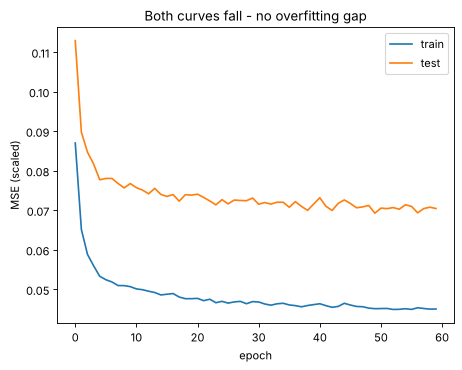

In [6]:
class Adam:
    def __init__(self, nets, lr=0.01):
        self.lr, self.t = lr, 0
        self.m = [{k: np.zeros_like(v) for k, v in n.p.items()} for n in nets]
        self.v = [{k: np.zeros_like(v) for k, v in n.p.items()} for n in nets]
    def step(self, nets, grads):
        self.t += 1
        for n, g, m, v in zip(nets, grads, self.m, self.v):
            for k in n.p:
                m[k] = 0.9 * m[k] + 0.1 * g[k]; v[k] = 0.999 * v[k] + 0.001 * g[k] ** 2
                n.p[k] -= self.lr * (m[k] / (1 - 0.9 ** self.t)) / (np.sqrt(v[k] / (1 - 0.999 ** self.t)) + 1e-8)

user_net, item_net = Tower(user_s.shape[1], seed=10), Tower(item_s.shape[1], seed=11)
opt = Adam([user_net, item_net], lr=0.01)
train_hist, test_hist = [], []
for epoch in range(60):
    order = np.random.default_rng(epoch).permutation(len(y_tr))
    for s in range(0, len(order), 128):                                  # mini-batches of 128
        b = order[s:s + 128]
        _, gu, gi = model_loss_and_grads(user_net, item_net, Xu_tr[b], Xm_tr[b], y_tr[b])
        opt.step([user_net, item_net], [gu, gi])
    train_hist.append(np.mean((np.sum(user_net.forward(Xu_tr) * item_net.forward(Xm_tr), 1) - y_tr) ** 2))
    test_hist.append(np.mean((np.sum(user_net.forward(Xu_te) * item_net.forward(Xm_te), 1) - y_te) ** 2))
    if epoch % 10 == 0 or epoch == 59:
        print(f"epoch {epoch:2d}: train MSE {train_hist[-1]:.4f} | test MSE {test_hist[-1]:.4f}")

plt.plot(train_hist, label="train"); plt.plot(test_hist, label="test"); plt.xlabel("epoch"); plt.ylabel("MSE (scaled)"); plt.legend()
plt.title("Both curves fall - no overfitting gap"); plt.show()

## How good is it, in stars?
Convert predictions back to the 0.5-5 star scale and compare with a baseline that always predicts the average rating.

In [7]:
pred_te = np.sum(user_net.forward(Xu_te) * item_net.forward(Xm_te), 1) * 2.25 + 2.75
true_te = y_te * 2.25 + 2.75
print(f"RMSE of predicting the global mean : {np.sqrt(np.mean((ratings.mean() - true_te) ** 2)):.3f} stars")
print(f"RMSE of the two-tower network      : {np.sqrt(np.mean((np.clip(pred_te, .5, 5) - true_te) ** 2)):.3f} stars")

RMSE of predicting the global mean : 1.265 stars
RMSE of the two-tower network      : 0.597 stars


## Predictions for a brand-new user
This is where content-based filtering beats collaborative filtering: a new user only needs to tell me their **genre preferences**, no rating history of the specific movies required. Say they love Sci-Fi and Action (4.5 stars) and dislike Romance and Drama (1.5).

In [8]:
new_user = np.array([4.5, 3.0, 1.5, 4.5, 1.5, 3.0])                 # avg rating for Action, Comedy, Drama, Sci-Fi, Romance, Horror
nu = (new_user - u_mu) / u_sd
vu = user_net.forward(nu[None, :])
scores = (item_net.forward(item_s) @ vu.T).ravel() * 2.25 + 2.75
for i in np.argsort(-scores)[:5]:
    names = [genres[g] for g in range(G) if item_genres[i, g]]
    print(f"movie {i:3d}  predicted {scores[i]:.2f}  genres: {', '.join(names)}")
print("...and the LOWEST scored:")
for i in np.argsort(scores)[:3]:
    names = [genres[g] for g in range(G) if item_genres[i, g]]
    print(f"movie {i:3d}  predicted {scores[i]:.2f}  genres: {', '.join(names)}")

movie 135  predicted 4.37  genres: Action, Sci-Fi
movie  73  predicted 4.32  genres: Action, Sci-Fi
movie  11  predicted 4.29  genres: Action, Sci-Fi
movie  34  predicted 4.13  genres: Sci-Fi
movie  86  predicted 4.11  genres: Sci-Fi
...and the LOWEST scored:
movie 106  predicted 1.46  genres: Drama, Romance, Horror
movie  14  predicted 1.50  genres: Romance
movie  31  predicted 1.50  genres: Romance


## Finding similar items
The item tower turns every movie into a 16-number vector. Movies with a small squared distance between vectors should be alike. Let me check that neighbours share genres.

In [9]:
V = item_net.forward(item_s)
def similar(i, k=4):
    d = np.sum((V - V[i]) ** 2, axis=1); d[i] = np.inf
    return np.argsort(d)[:k]

for i in [3, 40, 99]:
    print(f"movie {i}: {[genres[g] for g in range(G) if item_genres[i, g]]}")
    for j in similar(i):
        print(f"    neighbour {j}: {[genres[g] for g in range(G) if item_genres[j, g]]}")

movie 3: ['Drama', 'Sci-Fi']
    neighbour 145: ['Drama', 'Sci-Fi']
    neighbour 109: ['Drama', 'Sci-Fi']
    neighbour 0: ['Comedy', 'Drama', 'Sci-Fi']
    neighbour 78: ['Drama', 'Sci-Fi', 'Horror']
movie 40: ['Action']
    neighbour 100: ['Action']
    neighbour 68: ['Action']
    neighbour 98: ['Action']
    neighbour 87: ['Action', 'Comedy']
movie 99: ['Horror']
    neighbour 107: ['Horror']
    neighbour 23: ['Horror']
    neighbour 116: ['Horror']
    neighbour 42: ['Horror']


## The same model in Keras (what the course lab uses)
This cell is the TensorFlow version of everything I just wrote by hand - the framework does the backward pass for me. **I did not run this cell while preparing this notebook** (no TensorFlow where I built it), so run it in Colab where TensorFlow is installed.

In [ ]:
import tensorflow as tf
from tensorflow import keras

num_outputs = 32
user_NN = keras.models.Sequential([keras.layers.Dense(256, activation="relu"),
                                   keras.layers.Dense(128, activation="relu"),
                                   keras.layers.Dense(num_outputs)])
item_NN = keras.models.Sequential([keras.layers.Dense(256, activation="relu"),
                                   keras.layers.Dense(128, activation="relu"),
                                   keras.layers.Dense(num_outputs)])

input_user = keras.layers.Input(shape=(user_s.shape[1],))
vu = tf.linalg.l2_normalize(user_NN(input_user), axis=1)
input_item = keras.layers.Input(shape=(item_s.shape[1],))
vm = tf.linalg.l2_normalize(item_NN(input_item), axis=1)
output = keras.layers.Dot(axes=1)([vu, vm])

model = keras.Model([input_user, input_item], output)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss=keras.losses.MeanSquaredError())
model.fit([Xu_tr, Xm_tr], y_tr, epochs=30, validation_data=([Xu_te, Xm_te], y_te))

## Drawbacks / things to remember
- **Needs good features.** Everything depends on the user and item features I can engineer; the network can't invent information that isn't there.
- **Cold start is only half solved**: a new user/item with *features* works, one with none still doesn't.
- **Scoring cost**: to recommend I must run the item tower for every candidate item. Real systems precompute item vectors and use fast nearest-neighbour search (retrieval) before ranking.
- **Can only recommend what matches known taste** - it may trap users in a bubble; collaborative signals add surprise.
- Targets must be scaled to match the output range (here [-1, 1] because of the normalized dot product).